# ECE 285 - HW1: Chest X-Ray VAE 

In [1]:
# ==========================================
# 0. Install Dependencies & Mount Google Drive
# ==========================================
!pip install -q pytorch-ignite kaggle kagglehub

import os
import torch

# Mount Google Drive
# Note: If running via the VS Code / Antigravity Colab extension and drive.mount() hangs,
# press Ctrl+Shift+P and run: "Colab: Mount Google Drive to Server..."
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_DIR = "/content/drive/MyDrive/ECE285/HW1"
    os.makedirs(DRIVE_DIR, exist_ok=True)
    print(f"Google Drive mounted! Project folder: {DRIVE_DIR}")
except ImportError:
    DRIVE_DIR = "./ECE285/HW1"
    os.makedirs(DRIVE_DIR, exist_ok=True)
    print(f"Not running on Colab. Using local folder: {DRIVE_DIR}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted! Project folder: /content/drive/MyDrive/ECE285/HW1
Using device: cuda (NVIDIA A100-SXM4-40GB)


## 1. Download `chest_xray` Dataset from Kaggle into Google Drive
This cell downloads the **Chest X-Ray Images (Pneumonia)** dataset (`paultimothymooney/chest-xray-pneumonia`) from Kaggle and saves it in your Google Drive folder (`/content/drive/MyDrive/ECE285_HW1/chest_xray`) so you only need to download it once.

- **Authentication (if prompted)**:
  - **Option A (`kaggle.json` in Drive)**: Place your `kaggle.json` token in `/content/drive/MyDrive/kaggle.json`.
  - **Option B (`kagglehub`)**: Works automatically for public datasets, or call `kagglehub.login()` if prompted.

In [2]:
import shutil
import zipfile
import kagglehub

# Path in Google Drive where the dataset will be stored permanently
DRIVE_DATASET_DIR = os.path.join(DRIVE_DIR, "chest_xray")
DRIVE_ZIP_PATH = os.path.join(DRIVE_DIR, "chest-xray-pneumonia.zip")

# Fast local runtime path on Colab VM (avoids slow Google Drive FUSE file reads during training)
LOCAL_EXTRACT_DIR = "/content/chest_xray_data" if os.path.exists("/content") else "./chest_xray_data"

# 1. Check if kaggle.json exists on Google Drive and configure it automatically
kaggle_json_drive = "/content/drive/MyDrive/kaggle.json"
if os.path.exists(kaggle_json_drive):
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    shutil.copy(kaggle_json_drive, os.path.expanduser("~/.kaggle/kaggle.json"))
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    print("Loaded Kaggle credentials from /content/drive/MyDrive/kaggle.json")

# 2. Download dataset and save to Google Drive if not already in Drive
if not os.path.exists(os.path.join(DRIVE_DATASET_DIR, "train")) and not os.path.exists(DRIVE_ZIP_PATH):
    print("Downloading chest_xray dataset from Kaggle via kagglehub...")
    downloaded_path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
    print(f"Downloaded to cache: {downloaded_path}")

    # Locate the inner 'chest_xray' folder containing train/, val/, test/
    src_root = downloaded_path
    for root, dirs, _ in os.walk(downloaded_path):
        if {"train", "val", "test"}.issubset(set(dirs)):
            src_root = root
            break

    print(f"Saving dataset to Google Drive ({DRIVE_DATASET_DIR})...")
    shutil.copytree(src_root, DRIVE_DATASET_DIR, dirs_exist_ok=True)
    print("Dataset successfully saved to Google Drive!")
else:
    print(f"Dataset already found in Google Drive: {DRIVE_DATASET_DIR}")

# 3. Copy from Google Drive to fast local Colab storage for fast training I/O
LOCAL_DATA_ROOT = os.path.join(LOCAL_EXTRACT_DIR, "chest_xray")
if not os.path.exists(os.path.join(LOCAL_DATA_ROOT, "train")):
    if os.path.exists(os.path.join(DRIVE_DATASET_DIR, "train")):
        print(f"Copying dataset from Google Drive to local Colab disk ({LOCAL_DATA_ROOT}) for fast DataLoader I/O...")
        shutil.copytree(DRIVE_DATASET_DIR, LOCAL_DATA_ROOT, dirs_exist_ok=True)
    elif os.path.exists(DRIVE_ZIP_PATH):
        print(f"Extracting {DRIVE_ZIP_PATH} to {LOCAL_EXTRACT_DIR}...")
        with zipfile.ZipFile(DRIVE_ZIP_PATH, 'r') as zf:
            zf.extractall(LOCAL_EXTRACT_DIR)

# Final root_dir containing train/, val/, test/
DATA_ROOT = LOCAL_DATA_ROOT if os.path.exists(os.path.join(LOCAL_DATA_ROOT, "train")) else DRIVE_DATASET_DIR
print(f"\nReady! Using DATA_ROOT = {DATA_ROOT}")
for split in ["train", "val", "test"]:
    split_path = os.path.join(DATA_ROOT, split)
    print(f"  - {split}: exists={os.path.exists(split_path)} ({split_path})")

Dataset already found in Google Drive: /content/drive/MyDrive/ECE285/HW1/chest_xray

Ready! Using DATA_ROOT = /content/chest_xray_data/chest_xray
  - train: exists=True (/content/chest_xray_data/chest_xray/train)
  - val: exists=True (/content/chest_xray_data/chest_xray/val)
  - test: exists=True (/content/chest_xray_data/chest_xray/test)


## 2. Dataset & DataLoader

In [3]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import PIL.Image as Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import utils

from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore


class ChestXRayDataset(Dataset):
    """
    Loads all images from `root_dir/<split>/*/*` (ignoring class folders).
    """
    def __init__(self, root_dir, split="train", img_size=128):
        self.img_size = img_size
        self.image_paths = []
        for ext in ("*.jpeg", "*.jpg", "*.png"):
            pattern = os.path.join(root_dir, split, "*", ext)
            self.image_paths.extend(glob.glob(pattern))
        self.image_paths.sort()

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert("L")  # PIL Image (W, H), 1-channel grayscale
        img = img.resize((self.img_size, self.img_size))      # PIL Image (img_size, img_size)
        x = torch.tensor(np.array(img), dtype=torch.float32) / 255.0  # (img_size, img_size), values in [0, 1]
        x = x.unsqueeze(0)                                    # (1, img_size, img_size)
        return x


def get_dataloaders(root_dir, img_size=128, batch_size=64):
    train_ds = ChestXRayDataset(root_dir, split="train", img_size=img_size)
    val_ds   = ChestXRayDataset(root_dir, split="val",   img_size=img_size)
    test_ds  = ChestXRayDataset(root_dir, split="test",  img_size=img_size)

    print(f"Dataset counts -> Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, val_loader, test_loader

## 3. VAE Architecture & Loss Function

In [4]:
class VAE(nn.Module):
    def __init__(self, latent_dim=64, device=DEVICE):
        super().__init__()
        self.latent_dim = latent_dim
        self.device = device

        # Encoder: (B, 1, 128, 128) -> (B, 64, 16, 16)
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),    # (B, 16, 64, 64)
            nn.BatchNorm2d(16),
            nn.LeakyReLU(0.2),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),   # (B, 32, 32, 32)
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),   # (B, 64, 16, 16)
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
        )

        self.fc_mu = nn.Linear(64 * 16 * 16, latent_dim)             # (B, 16384) -> (B, latent_dim)
        self.fc_logvar = nn.Linear(64 * 16 * 16, latent_dim)         # (B, 16384) -> (B, latent_dim)

        # Decoder: (B, latent_dim) -> (B, 64, 16, 16) -> (B, 1, 128, 128)
        self.fc_decode = nn.Linear(latent_dim, 64 * 16 * 16)         # (B, latent_dim) -> (B, 16384)

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),  # (B, 32, 32, 32)
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),  # (B, 16, 64, 64)
            nn.BatchNorm2d(16),
            nn.ReLU(),

            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),   # (B, 1, 128, 128)
            nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder(x)               # (B, 64, 16, 16)
        h = torch.flatten(h, start_dim=1) # (B, 16384)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        h = F.relu(self.fc_decode(z))
        h = h.view(-1, 64, 16, 16)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decode(z)
        return recon_x, mu, logvar


def vae_loss(recon_x, x, mu, logvar, beta=1.0):
    batch_size = x.size(0)
    num_elements = x.numel()  # batch_size * C * H * W

    # Sum over pixels/latent dims (per sample) for backpropagation
    recon_sum = F.mse_loss(recon_x, x, reduction="sum") / batch_size
    kl_sum = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch_size
    loss_sum = recon_sum + beta * kl_sum

    # Mean over all elements for printing and plotting
    loss_mean = (loss_sum * batch_size) / num_elements
    return loss_sum, loss_mean, recon_sum, kl_sum

## 4. Training, Plotting & Evaluation Functions

In [5]:
def plot_loss_curves(train_losses, val_losses, start_epoch=0, save_path="loss_curves.png", show=False):
    plt.figure(figsize=(7, 4))
    epochs_range = range(start_epoch + 1, start_epoch + len(train_losses) + 1)
    plt.plot(epochs_range, train_losses, label="Train Loss (Mean)")
    plt.plot(epochs_range, val_losses, label="Val Loss (Mean)")
    plt.xlabel("Epoch")
    plt.ylabel("Mean VAE Loss (MSE + KL)")
    plt.title("Training and Validation Loss Curves")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(save_path, dpi=200)
    if show:
        plt.show()
    plt.close()


def train_vae(
    model,
    train_loader,
    val_loader,
    test_loader=None,
    start_epoch=0,
    epochs=50,
    lr=2e-4,
    min_lr=1e-6,
    beta=1.0,
    eval_every_k=10,
    device=DEVICE,
    save_dir=DRIVE_DIR,
    resume_checkpoint=None,
):
    model.to(device)

    # Load weights from checkpoint if specified
    if resume_checkpoint and os.path.exists(resume_checkpoint):
        ckpt = torch.load(resume_checkpoint, map_location=device)
        if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
            model.load_state_dict(ckpt["model_state_dict"])
        elif isinstance(ckpt, dict):
            model.load_state_dict(ckpt)
        print(f"Successfully loaded checkpoint: {resume_checkpoint} (Resuming at epoch {start_epoch + 1})")
    elif resume_checkpoint:
        print(f"Warning: Checkpoint '{resume_checkpoint}' not found! Starting without loading.")

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    total_steps = max(1, epochs - start_epoch)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps, eta_min=min_lr)

    train_losses, val_losses = [], []
    loss_plot_path = os.path.join(save_dir, "loss_curves.png")
    eval_log_path = os.path.join(save_dir, "test_eval_metrics.txt")

    for epoch in range(start_epoch + 1, epochs + 1):
        # --- Train ---
        model.train()
        running_train_loss = 0.0
        pbar = tqdm(train_loader, desc=f"Epoch [{epoch}/{epochs}]", leave=False)
        for x in pbar:
            x = x.to(device)
            optimizer.zero_grad()

            recon_x, mu, logvar = model(x)
            loss_sum, loss_mean, _, _ = vae_loss(recon_x, x, mu, logvar, beta=beta)

            # Backpropagate using sum loss
            loss_sum.backward()
            optimizer.step()

            # Track mean loss for printing & plotting
            running_train_loss += loss_mean.item()
            pbar.set_postfix(loss=f"{loss_mean.item():.5f}")

        avg_train_loss = running_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        # --- Validate ---
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for x in val_loader:
                x = x.to(device)
                recon_x, mu, logvar = model(x)
                _, loss_mean, _, _ = vae_loss(recon_x, x, mu, logvar, beta=beta)
                running_val_loss += loss_mean.item()

        avg_val_loss = running_val_loss / len(val_loader)
        val_losses.append(avg_val_loss)

        current_lr = optimizer.param_groups[0]["lr"]
        scheduler.step()

        print(f"Epoch [{epoch}/{epochs}] | LR: {current_lr:.2e} | Train Loss (Mean): {avg_train_loss:.5f} | Val Loss (Mean): {avg_val_loss:.5f}")
        plot_loss_curves(train_losses, val_losses, start_epoch=start_epoch, save_path=loss_plot_path, show=(epoch == epochs))

        # --- Every k epochs: save weights, generate 5 images, evaluate & log test metrics ---
        if eval_every_k and (epoch % eval_every_k == 0 or epoch == epochs):
   
            ckpt_path = os.path.join(save_dir, f"vae_chest_xray_epoch_{epoch}.pt")
            latest_path = os.path.join(save_dir, "vae_chest_xray.pt")
            torch.save(model.state_dict(), ckpt_path)
            torch.save(model.state_dict(), latest_path)
            print(f"  -> Saved model checkpoint to {ckpt_path}")

            samples_path = os.path.join(save_dir, f"generated_samples_epoch_{epoch}.png")
            generate_images(model, num_images=5, device=device, save_path=samples_path)

            if test_loader is not None:
                model.eval()
                running_test_loss = 0.0
                with torch.no_grad():
                    for x in test_loader:
                        x = x.to(device)
                        recon_x, mu, logvar = model(x)
                        _, loss_mean, _, _ = vae_loss(recon_x, x, mu, logvar, beta=beta)
                        running_test_loss += loss_mean.item()
                avg_test_loss = running_test_loss / len(test_loader)
                print(f"  -> [Test Eval @ Epoch {epoch}] Test Loss (Mean): {avg_test_loss:.5f}")
                incep_score, fid = compute_fid_and_is(model, test_loader, device=device)

                log_line = (
                    f"Epoch {epoch:03d}/{epochs:03d} | LR: {current_lr:.2e} | "
                    f"Train Loss: {avg_train_loss:.6f} | Val Loss: {avg_val_loss:.6f} | "
                    f"Test Loss: {avg_test_loss:.6f} | IS: {incep_score:.4f} | FID: {fid:.4f}\n"
                )
                with open(eval_log_path, "a") as f:
                    f.write(log_line)
                print(f"  -> Logged test metrics to {eval_log_path}")

    return train_losses, val_losses


def interpolate(batch):
    """Resize grayscale (B, 1, H, W) to 3-channel (B, 3, 299, 299) for InceptionV3."""
    if batch.size(1) == 1:
        batch = batch.repeat(1, 3, 1, 1)
    out = F.interpolate(batch, size=(299, 299), mode="bicubic", align_corners=False)
    return out.clamp(0.0, 1.0)


def compute_fid_and_is(model, test_loader, device=DEVICE):
    model.to(device)
    model.eval()

    def evaluation_step(engine, batch):
        with torch.no_grad():
            z = torch.randn(batch.size(0), model.latent_dim, device=device)
            generated = model.decode(z).cpu()
            fake = interpolate(generated)
            real = interpolate(batch)
            return fake, real

    fid_metric = FID(device=device)
    is_metric = InceptionScore(device=device, output_transform=lambda x: x[0])

    evaluator = Engine(evaluation_step)
    fid_metric.attach(evaluator, "fid")
    is_metric.attach(evaluator, "is")

    evaluator.run(test_loader)
    metrics = evaluator.state.metrics
    print(f"  -> Inception Score (IS): {metrics['is']:.4f} | FID: {metrics['fid']:.4f}")
    return metrics["is"], metrics["fid"]


def generate_images(model, num_images=5, device=DEVICE, save_path="generated_samples.png"):
    model.to(device)
    model.eval()
    with torch.no_grad():
        z = torch.randn(num_images, model.latent_dim, device=device)
        samples = model.decode(z).cpu()

    nrow = min(num_images, 5)
    grid = utils.make_grid(samples, nrow=nrow, padding=2)
    plt.figure(figsize=(2.2 * nrow, 2.5))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.axis("off")
    plt.title(f"Generated Chest X-Ray Images ({num_images} samples)")
    plt.tight_layout()
    plt.savefig(save_path, dpi=200)
    plt.show()
    plt.close()

## 5. Run VAE Training & Evaluation

Hyperparameters: {'root_dir': '/content/chest_xray_data/chest_xray', 'img_size': 128, 'batch_size': 32, 'latent_dim': 128, 'lr': 0.0004, 'min_lr': 4e-05, 'start_epoch': 0, 'epochs': 400, 'beta': 1.0, 'eval_every_k': 25}
Using device: cuda
Dataset counts -> Train: 5216 | Val: 16 | Test: 624


Epoch [1/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [1/400] | LR: 4.00e-04 | Train Loss (Mean): 0.03070 | Val Loss (Mean): 0.01519


Epoch [2/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [2/400] | LR: 4.00e-04 | Train Loss (Mean): 0.01394 | Val Loss (Mean): 0.01348


Epoch [3/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (43 outputs left out)

Epoch [24/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [24/400] | LR: 3.97e-04 | Train Loss (Mean): 0.00768 | Val Loss (Mean): 0.00736


Epoch [25/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [25/400] | LR: 3.97e-04 | Train Loss (Mean): 0.00760 | Val Loss (Mean): 0.00721
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_25.pt


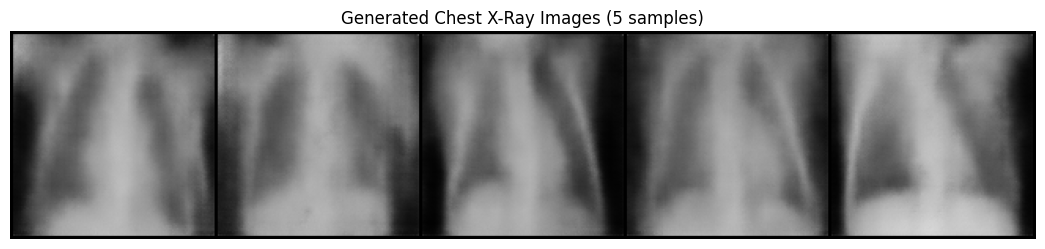

  -> [Test Eval @ Epoch 25] Test Loss (Mean): 0.00777
  -> Inception Score (IS): 1.4408 | FID: 0.1168
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [26/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [26/400] | LR: 3.97e-04 | Train Loss (Mean): 0.00761 | Val Loss (Mean): 0.00740


Epoch [27/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [27/400] | LR: 3.96e-04 | Train Loss (Mean): 0.00752 | Val Loss (Mean): 0.00716


Epoch [28/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (43 outputs left out)

Epoch [49/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [49/400] | LR: 3.87e-04 | Train Loss (Mean): 0.00700 | Val Loss (Mean): 0.00684


Epoch [50/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [50/400] | LR: 3.87e-04 | Train Loss (Mean): 0.00700 | Val Loss (Mean): 0.00681
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_50.pt


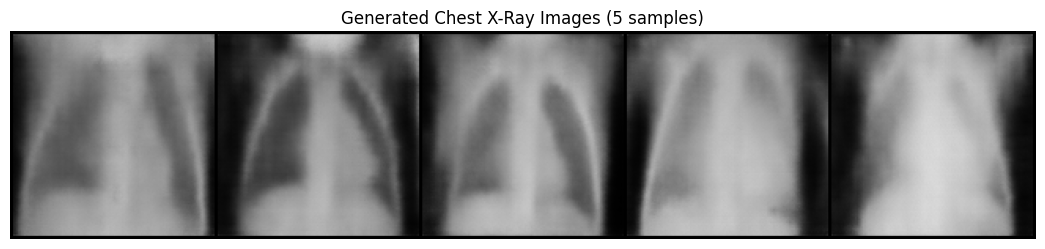

  -> [Test Eval @ Epoch 50] Test Loss (Mean): 0.00732
  -> Inception Score (IS): 1.6084 | FID: 0.1593
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [51/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [51/400] | LR: 3.86e-04 | Train Loss (Mean): 0.00694 | Val Loss (Mean): 0.00685


Epoch [52/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [52/400] | LR: 3.86e-04 | Train Loss (Mean): 0.00698 | Val Loss (Mean): 0.00700


Epoch [53/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (43 outputs left out)

Epoch [74/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [74/400] | LR: 3.71e-04 | Train Loss (Mean): 0.00668 | Val Loss (Mean): 0.00684


Epoch [75/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [75/400] | LR: 3.70e-04 | Train Loss (Mean): 0.00669 | Val Loss (Mean): 0.00672
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_75.pt


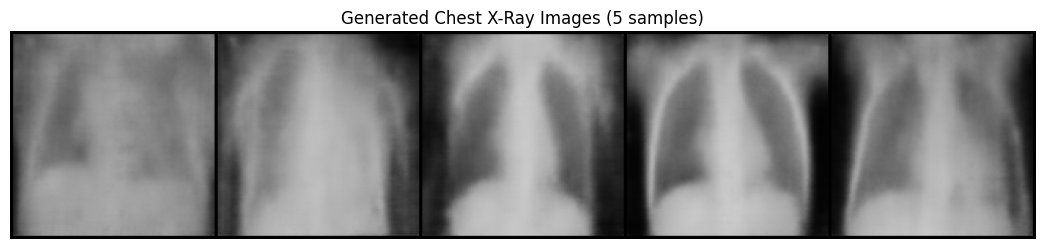

  -> [Test Eval @ Epoch 75] Test Loss (Mean): 0.00709
  -> Inception Score (IS): 1.7792 | FID: 0.1770
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [76/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [76/400] | LR: 3.70e-04 | Train Loss (Mean): 0.00667 | Val Loss (Mean): 0.00651


Epoch [77/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [77/400] | LR: 3.69e-04 | Train Loss (Mean): 0.00668 | Val Loss (Mean): 0.00653


Epoch [78/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (44 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa934e89bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7aa934e89bc0>  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

    Traceback (most recent call last):
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

AssertionError    : self._shutdown_workers()can only test a child process

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    Exception ignored in: if w.is_aliv

Epoch [99/400] | LR: 3.49e-04 | Train Loss (Mean): 0.00652 | Val Loss (Mean): 0.00629


Epoch [100/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [100/400] | LR: 3.48e-04 | Train Loss (Mean): 0.00653 | Val Loss (Mean): 0.00656
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_100.pt


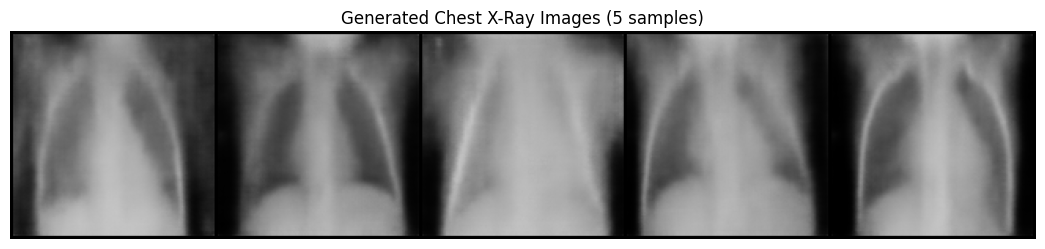

  -> [Test Eval @ Epoch 100] Test Loss (Mean): 0.00697
  -> Inception Score (IS): 1.7691 | FID: 0.1800
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [101/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [101/400] | LR: 3.47e-04 | Train Loss (Mean): 0.00647 | Val Loss (Mean): 0.00661


Epoch [102/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [102/400] | LR: 3.46e-04 | Train Loss (Mean): 0.00647 | Val Loss (Mean): 0.00643


Epoch [103/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (42 outputs left out)

Epoch [124/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [124/400] | LR: 3.22e-04 | Train Loss (Mean): 0.00636 | Val Loss (Mean): 0.00648


Epoch [125/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [125/400] | LR: 3.21e-04 | Train Loss (Mean): 0.00634 | Val Loss (Mean): 0.00631
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_125.pt


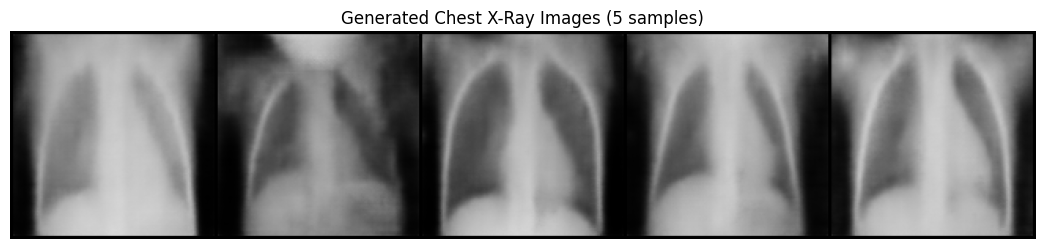

  -> [Test Eval @ Epoch 125] Test Loss (Mean): 0.00685
  -> Inception Score (IS): 1.8430 | FID: 0.2105
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [126/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [126/400] | LR: 3.20e-04 | Train Loss (Mean): 0.00633 | Val Loss (Mean): 0.00650


Epoch [127/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [127/400] | LR: 3.19e-04 | Train Loss (Mean): 0.00633 | Val Loss (Mean): 0.00646


Epoch [128/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (45 outputs left out)

Epoch [149/400] | LR: 2.91e-04 | Train Loss (Mean): 0.00624 | Val Loss (Mean): 0.00641


Epoch [150/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa934e89bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa934e89bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch [150/400] | LR: 2.90e-04 | Train Loss (Mean): 0.00625 | Val Loss (Mean): 0.00627
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_150.pt


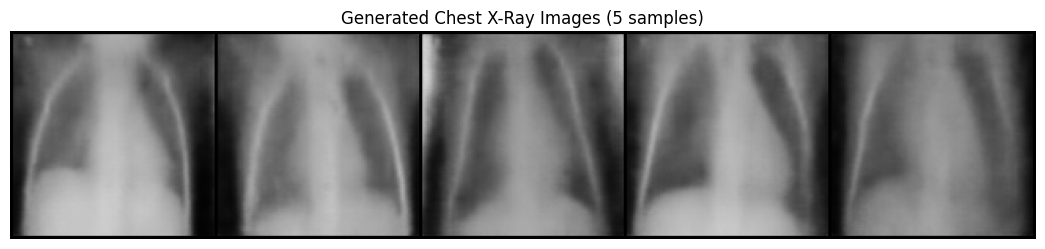

  -> [Test Eval @ Epoch 150] Test Loss (Mean): 0.00681
  -> Inception Score (IS): 1.8559 | FID: 0.1882
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [151/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [151/400] | LR: 2.89e-04 | Train Loss (Mean): 0.00622 | Val Loss (Mean): 0.00643


Epoch [152/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [152/400] | LR: 2.88e-04 | Train Loss (Mean): 0.00624 | Val Loss (Mean): 0.00647


Epoch [153/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (41 outputs left out)

Epoch [174/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [174/400] | LR: 2.58e-04 | Train Loss (Mean): 0.00612 | Val Loss (Mean): 0.00645


Epoch [175/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [175/400] | LR: 2.57e-04 | Train Loss (Mean): 0.00614 | Val Loss (Mean): 0.00634
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_175.pt


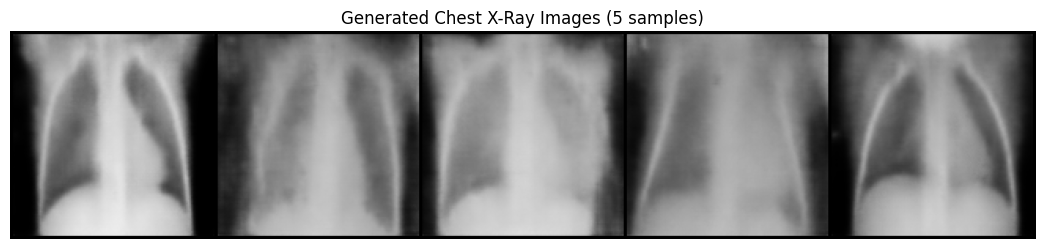

  -> [Test Eval @ Epoch 175] Test Loss (Mean): 0.00682
  -> Inception Score (IS): 1.9252 | FID: 0.2185
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [176/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [176/400] | LR: 2.55e-04 | Train Loss (Mean): 0.00614 | Val Loss (Mean): 0.00643


Epoch [177/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [177/400] | LR: 2.54e-04 | Train Loss (Mean): 0.00615 | Val Loss (Mean): 0.00638


Epoch [178/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (42 outputs left out)

Epoch [199/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [199/400] | LR: 2.23e-04 | Train Loss (Mean): 0.00607 | Val Loss (Mean): 0.00629


Epoch [200/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [200/400] | LR: 2.21e-04 | Train Loss (Mean): 0.00605 | Val Loss (Mean): 0.00643
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_200.pt


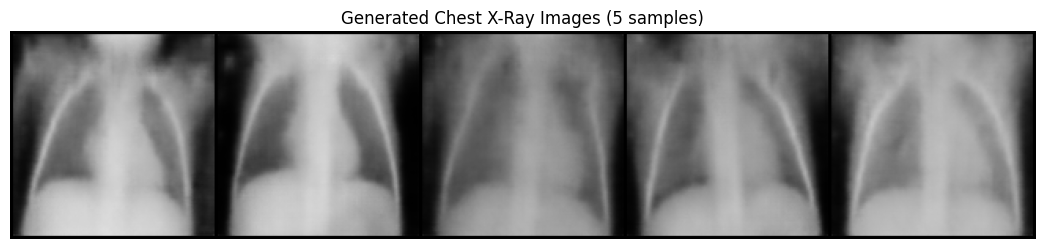

  -> [Test Eval @ Epoch 200] Test Loss (Mean): 0.00681
  -> Inception Score (IS): 1.8759 | FID: 0.2037
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [201/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [201/400] | LR: 2.20e-04 | Train Loss (Mean): 0.00606 | Val Loss (Mean): 0.00636


Epoch [202/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [202/400] | LR: 2.19e-04 | Train Loss (Mean): 0.00605 | Val Loss (Mean): 0.00635


Epoch [203/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (43 outputs left out)

Epoch [224/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [224/400] | LR: 1.88e-04 | Train Loss (Mean): 0.00601 | Val Loss (Mean): 0.00643


Epoch [225/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [225/400] | LR: 1.86e-04 | Train Loss (Mean): 0.00599 | Val Loss (Mean): 0.00639
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_225.pt


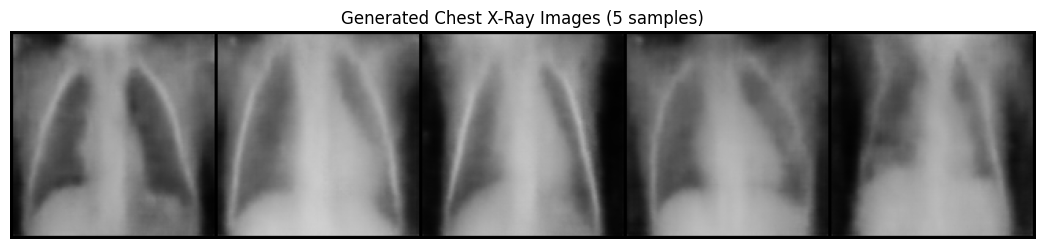

  -> [Test Eval @ Epoch 225] Test Loss (Mean): 0.00678
  -> Inception Score (IS): 1.8939 | FID: 0.2181
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [226/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [226/400] | LR: 1.85e-04 | Train Loss (Mean): 0.00599 | Val Loss (Mean): 0.00625


Epoch [227/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [227/400] | LR: 1.83e-04 | Train Loss (Mean): 0.00599 | Val Loss (Mean): 0.00633


Epoch [228/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (41 outputs left out)

Epoch [249/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [249/400] | LR: 1.54e-04 | Train Loss (Mean): 0.00595 | Val Loss (Mean): 0.00628


Epoch [250/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [250/400] | LR: 1.52e-04 | Train Loss (Mean): 0.00593 | Val Loss (Mean): 0.00647
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_250.pt


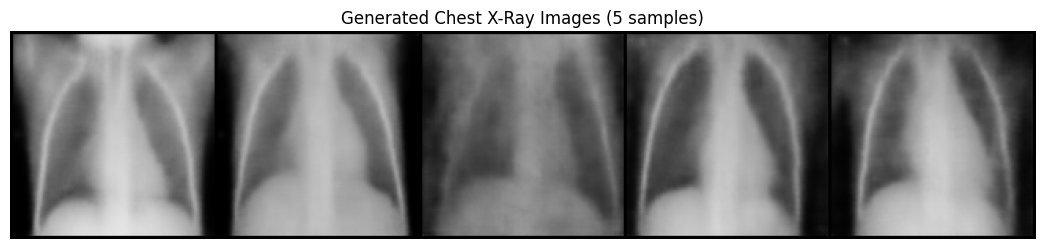

  -> [Test Eval @ Epoch 250] Test Loss (Mean): 0.00680
  -> Inception Score (IS): 1.9754 | FID: 0.2265
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [251/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [251/400] | LR: 1.51e-04 | Train Loss (Mean): 0.00594 | Val Loss (Mean): 0.00627


Epoch [252/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [252/400] | LR: 1.50e-04 | Train Loss (Mean): 0.00594 | Val Loss (Mean): 0.00656


Epoch [253/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (42 outputs left out)

Epoch [274/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [274/400] | LR: 1.22e-04 | Train Loss (Mean): 0.00589 | Val Loss (Mean): 0.00634


Epoch [275/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [275/400] | LR: 1.21e-04 | Train Loss (Mean): 0.00589 | Val Loss (Mean): 0.00646
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_275.pt


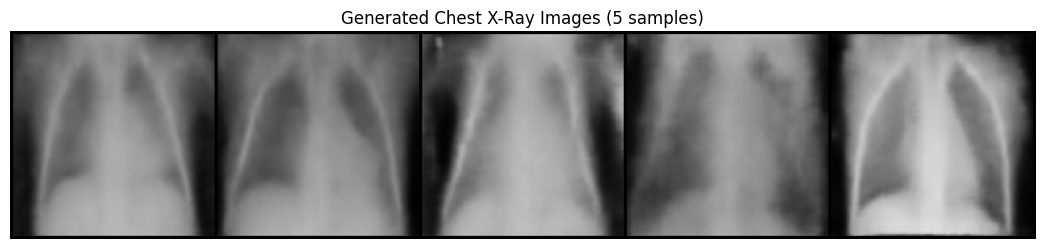

  -> [Test Eval @ Epoch 275] Test Loss (Mean): 0.00679
  -> Inception Score (IS): 1.9621 | FID: 0.2216
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [276/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [276/400] | LR: 1.20e-04 | Train Loss (Mean): 0.00589 | Val Loss (Mean): 0.00641


Epoch [277/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [277/400] | LR: 1.19e-04 | Train Loss (Mean): 0.00590 | Val Loss (Mean): 0.00628


Epoch [278/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (43 outputs left out)

Epoch [299/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [299/400] | LR: 9.47e-05 | Train Loss (Mean): 0.00586 | Val Loss (Mean): 0.00641


Epoch [300/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [300/400] | LR: 9.37e-05 | Train Loss (Mean): 0.00585 | Val Loss (Mean): 0.00630
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_300.pt


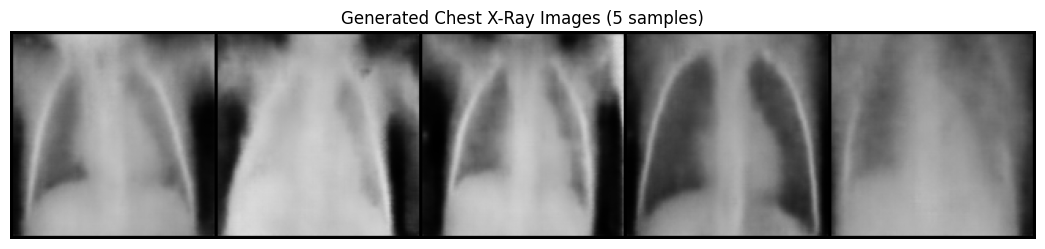

  -> [Test Eval @ Epoch 300] Test Loss (Mean): 0.00680
  -> Inception Score (IS): 1.9312 | FID: 0.2143
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [301/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [301/400] | LR: 9.27e-05 | Train Loss (Mean): 0.00584 | Val Loss (Mean): 0.00639


Epoch [302/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [302/400] | LR: 9.17e-05 | Train Loss (Mean): 0.00584 | Val Loss (Mean): 0.00643


Epoch [303/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (43 outputs left out)

Epoch [324/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [324/400] | LR: 7.19e-05 | Train Loss (Mean): 0.00581 | Val Loss (Mean): 0.00639


Epoch [325/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [325/400] | LR: 7.11e-05 | Train Loss (Mean): 0.00582 | Val Loss (Mean): 0.00636
  -> Saved model checkpoint to /content/drive/MyDrive/ECE285/HW1/vae_chest_xray_epoch_325.pt


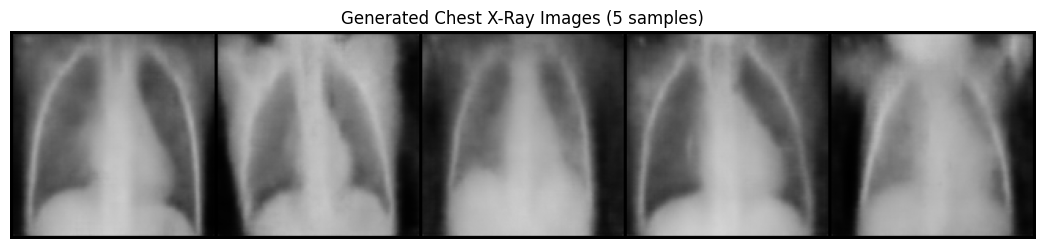

  -> [Test Eval @ Epoch 325] Test Loss (Mean): 0.00681
  -> Inception Score (IS): 1.9759 | FID: 0.2262
  -> Logged test metrics to /content/drive/MyDrive/ECE285/HW1/test_eval_metrics.txt


Epoch [326/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [326/400] | LR: 7.03e-05 | Train Loss (Mean): 0.00582 | Val Loss (Mean): 0.00628


Epoch [327/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [327/400] | LR: 6.96e-05 | Train Loss (Mean): 0.00582 | Val Loss (Mean): 0.00650


Epoch [328/400]:   0%|          | 0/163 [00:00<?, ?it/s]

... (2 outputs left out)

Epoch [329/400] | LR: 6.80e-05 | Train Loss (Mean): 0.00581 | Val Loss (Mean): 0.00626


Epoch [330/400]:   0%|          | 0/163 [00:00<?, ?it/s]

Epoch [330/400] | LR: 6.73e-05 | Train Loss (Mean): 0.00581 | Val Loss (Mean): 0.00640


Epoch [331/400]:   0%|          | 0/163 [00:00<?, ?it/s]

In [ ]:
HYPERPARAMS = {
    "root_dir": DATA_ROOT,
    "img_size": 128,
    "batch_size": 32,
    "latent_dim": 128,
    "lr": 4e-4,              # Learning rate for continued training (or fine-tuning)
    "min_lr": 4e-5,
    "start_epoch": 0,       # Start continuing from epoch 100
    "epochs": 400,            # Target total epochs (trains from 101 to 200)
    "beta": 1.0,
    "eval_every_k": 25  # or "vae_chest_xray.pt",
    # "resume_checkpoint" : 
}
print("Hyperparameters:", HYPERPARAMS)
print(f"Using device: {DEVICE}")

# Load data
train_loader, val_loader, test_loader = get_dataloaders(
    root_dir=HYPERPARAMS["root_dir"],
    img_size=HYPERPARAMS["img_size"],
    batch_size=HYPERPARAMS["batch_size"],
)

# Initialize & train VAE (loads weights from checkpoint if specified)
model = VAE(latent_dim=HYPERPARAMS["latent_dim"], device=DEVICE).to(DEVICE)
train_losses, val_losses = train_vae(
    model,
    train_loader,
    val_loader,
    test_loader=test_loader,
    start_epoch=HYPERPARAMS.get("start_epoch", 0),
    epochs=HYPERPARAMS["epochs"],
    lr=HYPERPARAMS["lr"],
    min_lr=HYPERPARAMS["min_lr"],
    beta=HYPERPARAMS["beta"],
    eval_every_k=HYPERPARAMS["eval_every_k"],
    resume_checkpoint=HYPERPARAMS.get("resume_checkpoint", None),
    device=DEVICE,
    save_dir=DRIVE_DIR,
)

# Save final model weights & outputs directly to Google Drive
weights_path = os.path.join(DRIVE_DIR, "vae_chest_xray.pt")
samples_path = os.path.join(DRIVE_DIR, "generated_samples.png")
torch.save(model.state_dict(), weights_path)
print(f"Saved model weights to {weights_path}")

# Generate sample chest X-rays
generate_images(model, num_images=7, device=DEVICE, save_path=samples_path)

# Evaluate IS and FID on test set
compute_fid_and_is(model, test_loader, device=DEVICE)